# Lab 1–3: เปิดฝากระโปรง LLM (ภาษาไทย)
**Generative AI · ช่วงบ่าย · Notebook 1**

Notebook นี้ใช้ **โมเดลที่เข้าใจภาษาไทย** และ **ตัวอย่างภาษาไทย** ทั้งหมด เพื่อดูว่า LLM ทำงานอย่างไร ด้วยภาพและการเปรียบเทียบ

| Lab | ดูอะไร | เปรียบเทียบอะไร |
|---|---|---|
| 1 | Tokenizer & Embedding | tokenizer อังกฤษ vs ไทย vs หลายภาษา · กลุ่มคำไทยใน embedding |
| 2 | ข้างใน LLM | การเขียนทีละ token · attention ของ encoder vs decoder · **base vs instruction model** · มี/ไม่มีความจำ · มี/ไม่มี context |
| 3 | Temperature & Top-p | การกระจายความน่าจะเป็น · จำนวนตัวเลือกของ top-p · ความหลากหลายของข้อความ |

**โมเดลที่ใช้** (รันได้บน Colab ฟรี)
| ชื่อในแล็บ | โมเดล | ตระกูล (ตอนเช้า) | หมายเหตุ |
|---|---|---|---|
| **Typhoon-Base** | `typhoon-ai/llama3.2-typhoon2-1b` | Decoder-only · **base model** | LLM ภาษาไทยจาก SCB 10X (ต่อยอด Llama 3.2) ผ่าน pretraining อย่างเดียว |
| **Typhoon-Instruct** | `typhoon-ai/llama3.2-typhoon2-1b-instruct` | Decoder-only · **instruction model** | ตัวเดียวกันที่ฝึกต่อให้ทำตามคำสั่งและคุยได้ |
| **WangchanBERTa** | `poom-sci/WangchanBERTa-finetuned-sentiment` | Encoder-only (แบบ BERT) | โมเดลภาษาไทยจาก VISTEC-depa ใช้ดู tokenizer และ attention |
| GPT-2 (เฉพาะ tokenizer) | `openai-community/gpt2` | — | ใช้เทียบว่า tokenizer ภาษาอังกฤษจัดการภาษาไทยอย่างไร |

> ส่วนหนึ่งดัดแปลงจากแล็บ *Exploring Generative AI Libraries* (IBM Skills Network)

## Lab 0 · เตรียมเครื่อง
1. เมนู **Runtime → Change runtime type → T4 GPU → Save** (แนะนำมาก เพราะใช้โมเดล 1.2B พารามิเตอร์ 2 ตัว)
2. รันเซลล์ตามลำดับด้วย `Shift + Enter`

เซลล์แรกติดตั้ง `pythainlp` (ชุดเครื่องมือภาษาไทย) และตั้งฟอนต์ไทยให้กราฟ

In [1]:
%pip install -q pythainlp

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ตั้งฟอนต์ภาษาไทยให้กราฟ (Colab ไม่มีฟอนต์ไทยมาให้ ถ้าไม่ตั้ง ตัวอักษรไทยในกราฟจะเป็นสี่เหลี่ยม)
import os, subprocess, urllib.request
import matplotlib.pyplot as plt, matplotlib.font_manager as fm

def setup_thai_font():
    font_file = "Sarabun-Regular.ttf"
    try:
        if not os.path.exists(font_file):
            urllib.request.urlretrieve("https://raw.githubusercontent.com/google/fonts/main/ofl/sarabun/Sarabun-Regular.ttf", font_file)
        fm.fontManager.addfont(font_file)
        return fm.FontProperties(fname=font_file).get_name()
    except Exception:
        try:   # สำรอง: ติดตั้งฟอนต์ไทยจาก Ubuntu
            subprocess.run("apt-get -qq install -y fonts-thai-tlwg > /dev/null", shell=True, check=True)
            for f in fm.findSystemFonts():
                if "Loma" in f: fm.fontManager.addfont(f)
            return "Loma"
        except Exception:
            return None

thai_font = setup_thai_font()
if thai_font:
    plt.rcParams["font.family"] = [thai_font, "DejaVu Sans"]
print("ฟอนต์ไทยในกราฟ:", thai_font or "ไม่พบ (ตัวอักษรไทยในกราฟอาจแสดงเป็นสี่เหลี่ยม)")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.unicode_minus": False})

import torch, transformers, html
import numpy as np, pandas as pd
from IPython.display import HTML, display
print("transformers:", transformers.__version__, "| torch:", torch.__version__)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ ใช้ GPU:", torch.cuda.get_device_name(0)) if device == "cuda" else print("⚠️ ใช้ CPU (ช้ามาก แนะนำให้เปิด GPU)")
pd.set_option("display.max_colwidth", None)

ฟอนต์ไทยในกราฟ: Sarabun


/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers: 4.57.6 | torch: 2.8.0
⚠️ ใช้ CPU (ช้ามาก แนะนำให้เปิด GPU)


### โหลดโมเดล (ครั้งแรกใช้ 3–5 นาที)
- บน GPU ใช้ `float32` (แม่นยำ ใช้หน่วยความจำ ~5 GB ต่อโมเดล T4 รับได้) · บน CPU ใช้ `bfloat16` เพื่อประหยัด RAM
- `attn_implementation="eager"` ทำให้ดึงค่า attention ออกมาวาดภาพได้ใน Lab 2

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel

dtype = torch.float32 if device == "cuda" else torch.bfloat16

def load(repo_id, kind):
    tok = AutoTokenizer.from_pretrained(repo_id)
    cls = AutoModelForCausalLM if kind == "causal" else AutoModel
    model = cls.from_pretrained(repo_id, dtype=dtype, attn_implementation="eager").to(device).eval()
    print(f"✅ {repo_id:48s} {sum(p.numel() for p in model.parameters())/1e6:7.0f}M params")
    return tok, model

BASE, INST = "Typhoon-Base", "Typhoon-Instruct"
llms = {
    BASE: load("typhoon-ai/llama3.2-typhoon2-1b", "causal"),
    INST: load("typhoon-ai/llama3.2-typhoon2-1b-instruct", "causal"),
}
wc_tok, wangchan = load("poom-sci/WangchanBERTa-finetuned-sentiment", "encoder")
gpt2_tok = AutoTokenizer.from_pretrained("openai-community/gpt2")

✅ typhoon-ai/llama3.2-typhoon2-1b                     1236M params
✅ typhoon-ai/llama3.2-typhoon2-1b-instruct            1236M params


Some weights of CamembertModel were not initialized from the model checkpoint at poom-sci/WangchanBERTa-finetuned-sentiment and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ poom-sci/WangchanBERTa-finetuned-sentiment           105M params


---
## Lab 1 · Tokenizer & Embedding
ช่วงเช้า: Transformer เริ่มจาก **① Tokenization → ② Embedding**
โมเดลไม่ได้อ่านตัวอักษร แต่อ่าน **token** (คำหรือเศษคำ) → เลข **token id** → เปิดตาราง embedding ได้ **เวกเตอร์**

### 1.1 Tokenizer 3 แบบ ตัดข้อความภาษาไทยต่างกันอย่างไร
| Tokenizer | ฝึกมากับ |
|---|---|
| **GPT-2** | ภาษาอังกฤษเกือบทั้งหมด |
| **WangchanBERTa** | ภาษาไทยโดยเฉพาะ (sentencepiece) |
| **Typhoon2** | หลายภาษา รวมภาษาไทย (tokenizer ของ Llama 3.2) |

แต่ละสีคือ 1 token · `␣` คือช่องว่าง

In [4]:
TOKENIZERS = {"GPT-2": gpt2_tok, "WangchanBERTa": wc_tok, "Typhoon2": llms[BASE][0]}
COLORS = ["#FFE0B2", "#C8E6C9", "#BBDEFB", "#F8BBD0", "#D1C4E9", "#FFF59D"]

def pieces_of(tokenizer, text):
    ids = tokenizer.encode(text, add_special_tokens=False)
    return ids, [tokenizer.decode([i]) for i in ids]

def compare_tokenizers(text):
    rows = []
    for name, tk in TOKENIZERS.items():
        ids, pieces = pieces_of(tk, text)
        spans = "".join(
            f'<span style="background:{COLORS[k % len(COLORS)]};padding:2px 3px;margin:1px;border-radius:4px;'
            f'font-family:monospace">{html.escape(p).replace(" ", "␣") or "∅"}</span>' for k, p in enumerate(pieces))
        rows.append(f'<div style="margin:6px 0"><b style="display:inline-block;width:125px">{name}</b>'
                    f'<span style="display:inline-block;width:80px;color:#777">{len(ids)} tokens</span>{spans}</div>')
    display(HTML(f'<div style="font-size:15px"><div style="margin-bottom:6px">📝 <i>{html.escape(text)}</i></div>{"".join(rows)}</div>'))

compare_tokenizers("ฉันชอบเรียนปัญญาประดิษฐ์ที่มหาวิทยาลัย")
compare_tokenizers("วันนี้อากาศที่กรุงเทพฯ ร้อนมาก")
compare_tokenizers("I really enjoy studying artificial intelligence.")

**อ่านผลอย่างไร**
- **GPT-2** ไม่รู้จักภาษาไทย จึงหั่นลงถึงระดับ *ไบต์* (อักษรไทย 1 ตัว = 3 ไบต์ใน UTF-8) ชิ้นที่แสดงเป็น `�` คือเศษของตัวอักษร → ใช้ token จำนวนมาก และแต่ละ token ไม่มีความหมาย
- **WangchanBERTa** ฝึกกับภาษาไทย ตัดออกมาเป็นคำหรือหน่วยที่มีความหมาย เช่น `ปัญญา` `ประดิษฐ์` · สัญลักษณ์ `▁` คือจุดเริ่มคำของ sentencepiece
- **Typhoon2** อยู่ตรงกลาง: รู้จักภาษาไทยพอสมควร แต่บางคำยังถูกหั่นย่อยกว่า WangchanBERTa
- ภาษาอังกฤษ (ประโยคสุดท้าย): GPT-2 และ Typhoon2 ตัดได้กระชับ เพราะฝึกภาษาอังกฤษมามาก

### 1.2 นับให้เห็นชัด: ภาษาไทยใช้ token มากกว่าภาษาอังกฤษเท่าไร
ประโยค 3 คู่ ความหมายเดียวกัน

,อังกฤษ,ไทย,ไทย/อังกฤษ
tokenizer,,,
GPT-2,24,176,7.33
WangchanBERTa,64,17,0.27
Typhoon2,24,41,1.71


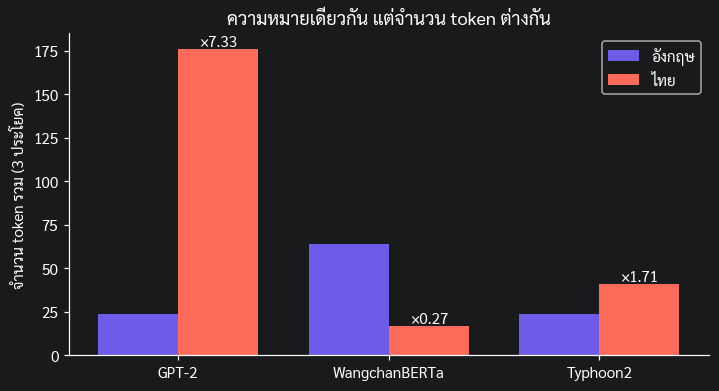

In [5]:
pairs = [
    ("I really enjoy studying artificial intelligence.", "ฉันชอบเรียนปัญญาประดิษฐ์มาก"),
    ("The weather in Bangkok is very hot today.",        "วันนี้อากาศที่กรุงเทพร้อนมาก"),
    ("Please send me the report by Friday.",             "กรุณาส่งรายงานให้ฉันภายในวันศุกร์"),
]
rows = []
for name, tk in TOKENIZERS.items():
    en = sum(len(tk.encode(e, add_special_tokens=False)) for e, _ in pairs)
    th = sum(len(tk.encode(t, add_special_tokens=False)) for _, t in pairs)
    rows.append({"tokenizer": name, "อังกฤษ": en, "ไทย": th, "ไทย/อังกฤษ": round(th / en, 2)})
df_counts = pd.DataFrame(rows).set_index("tokenizer")
display(df_counts)

x = np.arange(len(df_counts)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(x - w/2, df_counts["อังกฤษ"], w, label="อังกฤษ", color="#6C5CE7")
ax.bar(x + w/2, df_counts["ไทย"], w, label="ไทย", color="#FF6B5B")
for i, r in enumerate(df_counts["ไทย/อังกฤษ"]):
    ax.text(i + w/2, df_counts["ไทย"].iloc[i], f"×{r}", ha="center", va="bottom")
ax.set_xticks(x, df_counts.index); ax.set_ylabel("จำนวน token รวม (3 ประโยค)")
ax.set_title("ความหมายเดียวกัน แต่จำนวน token ต่างกัน"); ax.legend(); plt.show()

**อ่านผลอย่างไร:** ตัวเลข `×` คือ "ภาษาไทยใช้ token มากกว่าอังกฤษกี่เท่า"
- GPT-2 ใช้ token กับภาษาไทยมากกว่าหลายเท่า · WangchanBERTa ใช้น้อยที่สุดสำหรับภาษาไทย · Typhoon2 อยู่ระหว่างกลาง
- ผลในโลกจริง: LLM คิดราคาและจำกัดความยาว (context window) เป็นจำนวน token → **โมเดลที่ฝึกภาษาไทยมา ทั้งถูกกว่าและอ่านข้อความไทยได้ยาวกว่า**

### 1.3 Embedding: คำไทยกลุ่มเดียวกันอยู่ใกล้กันไหม
token id ใช้เปิดตาราง embedding ของ Typhoon2 (ขนาด ~128,000 แถว × 2,048 คอลัมน์) ได้เวกเตอร์ต่อ token
ถ้าคำถูกหั่นหลาย token ใช้ค่าเฉลี่ย แล้วย่อเหลือ 2 มิติด้วย **PCA** เพื่อวาดดู

ตาราง embedding ของ Typhoon2: (128256, 2048)


/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/teerapong/PycharmProjects/WelcomeScreen/.venv/l

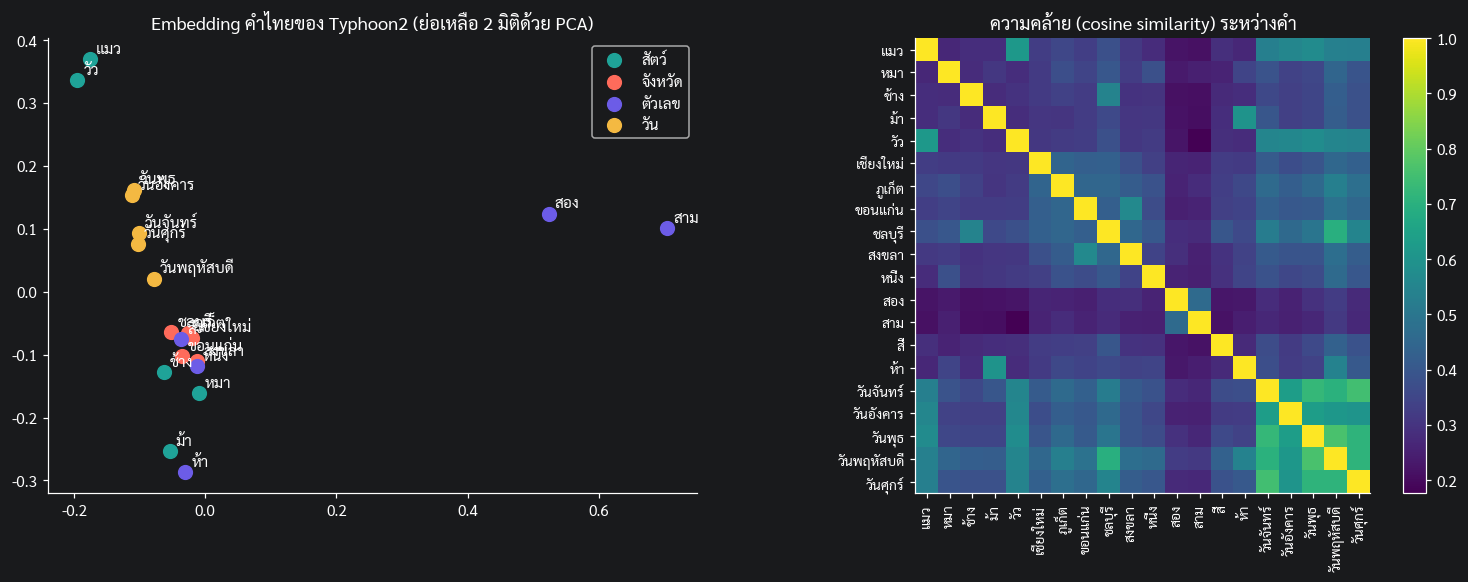

In [6]:
from sklearn.decomposition import PCA
import torch.nn.functional as F

ty_tok, ty_base = llms[BASE]
emb_table = ty_base.get_input_embeddings().weight.detach().float().cpu()
print("ตาราง embedding ของ Typhoon2:", tuple(emb_table.shape))

def word_vector(word):
    ids = ty_tok.encode(word, add_special_tokens=False)
    return emb_table[ids].mean(dim=0)

groups = {
    "สัตว์":   ["แมว", "หมา", "ช้าง", "ม้า", "วัว"],
    "จังหวัด": ["เชียงใหม่", "ภูเก็ต", "ขอนแก่น", "ชลบุรี", "สงขลา"],
    "ตัวเลข":  ["หนึ่ง", "สอง", "สาม", "สี่", "ห้า"],
    "วัน":     ["วันจันทร์", "วันอังคาร", "วันพุธ", "วันพฤหัสบดี", "วันศุกร์"],
}
words  = [w for ws in groups.values() for w in ws]
labels = [g for g, ws in groups.items() for _ in ws]
vecs   = torch.stack([word_vector(w) for w in words])
xy     = PCA(n_components=2).fit_transform(vecs.numpy())

palette = dict(zip(groups, ["#1FA398", "#FF6B5B", "#6C5CE7", "#F4B942"]))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
for g in groups:
    m = [l == g for l in labels]
    axes[0].scatter(xy[m, 0], xy[m, 1], s=80, color=palette[g], label=g)
for (x_, y_), w in zip(xy, words):
    axes[0].annotate(w, (x_, y_), textcoords="offset points", xytext=(4, 4), fontsize=10)
axes[0].set_title("Embedding คำไทยของ Typhoon2 (ย่อเหลือ 2 มิติด้วย PCA)"); axes[0].legend()

sim = F.cosine_similarity(vecs[:, None, :], vecs[None, :, :], dim=-1).numpy()
im = axes[1].imshow(sim, cmap="viridis")
axes[1].set_xticks(range(len(words)), words, rotation=90, fontsize=9)
axes[1].set_yticks(range(len(words)), words, fontsize=9)
axes[1].set_title("ความคล้าย (cosine similarity) ระหว่างคำ"); plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร**
- **ภาพซ้าย:** คำกลุ่มเดียวกัน (สีเดียวกัน) มักอยู่ใกล้กัน แม้ไม่มีใครบอกโมเดลว่า "แมว" กับ "หมา" เป็นสัตว์ — มันเรียนรู้จากการที่คำเหล่านี้ปรากฏในบริบทคล้ายกัน
- **ภาพขวา:** ช่องสว่าง = คล้ายกันมาก จะเห็นบล็อกสว่างตามแนวทแยงเป็นกลุ่ม (เช่น วันทั้ง 5 วันคล้ายกันมาก เพราะมีคำว่า "วัน" ร่วมกันด้วย)
- ข้อจำกัด: คำไทยที่ถูกหั่นหลาย token ถูกเฉลี่ยรวมกัน ภาพจึงไม่สมบูรณ์แบบ และนี่เป็นเพียง embedding **ชั้นแรก** ที่ยังไม่มีบริบท — ความหมายตามบริบทมาจาก attention (Lab 2.3)

---
## Lab 2 · ข้างใน LLM
### 2.1 ข้อความ → id → โมเดล → id → ข้อความ
**Instruction model** ต้องใส่ข้อความใน **chat template** (รูปแบบบทสนทนาที่ใช้ตอนฝึก) ด้วย `apply_chat_template()` จะเห็นว่ามี token พิเศษบอกบทบาท (system / user / assistant) แทรกอยู่

In [7]:
tok, model = llms[INST]
messages = [{"role": "user", "content": "เมืองหลวงของประเทศญี่ปุ่นคืออะไร ตอบสั้นๆ"}]

inputs = tok.apply_chat_template(messages, add_generation_prompt=True,
                                 return_tensors="pt", return_dict=True).to(device)   # ① ข้อความ + template → token ids
with torch.no_grad():
    output_ids = model.generate(**inputs, max_new_tokens=30, do_sample=False,
                                pad_token_id=tok.eos_token_id)                        # ② สร้าง id ใหม่ทีละตัว
n = inputs["input_ids"].shape[1]
answer = tok.decode(output_ids[0][n:], skip_special_tokens=True)                      # ③ ตัด prompt ออก แล้ว id → ข้อความ

print("① สิ่งที่โมเดลเห็นจริง (หลังใส่ chat template):\n")
print(tok.decode(inputs["input_ids"][0]))
print(f"\n① จำนวน token ขาเข้า: {n}")
print("② id ที่สร้างใหม่:", output_ids[0][n:].tolist())
print("③ คำตอบ:", answer)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


① สิ่งที่โมเดลเห็นจริง (หลังใส่ chat template):

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

<|eot_id|><|start_header_id|>user<|end_header_id|>

เมืองหลวงของประเทศญี่ปุ่นคืออะไร ตอบสั้นๆ<|eot_id|><|start_header_id|>assistant<|end_header_id|>



① จำนวน token ขาเข้า: 52
② id ที่สร้างใหม่: [101142, 103413, 115919, 100618, 105208, 100630, 48271, 55784, 101880, 124642, 84681, 107781, 100657, 107692, 128009]
③ คำตอบ: เมืองหลวงของประเทศญี่ปุ่นคือโตเกียว


**อธิบาย**
- `apply_chat_template(...)` ห่อข้อความของเราด้วย token พิเศษ เช่น `<|start_header_id|>user<|end_header_id|>` และ `add_generation_prompt=True` เติมหัวของ assistant ไว้ท้าย เพื่อบอกว่า "ถึงตาโมเดลตอบแล้ว"
- `return_dict=True` คืนทั้ง `input_ids` และ `attention_mask` · `.to(device)` ย้ายไป GPU · `do_sample=False` = เลือกคำที่น่าจะเป็นที่สุดเสมอ (ผลเหมือนเดิมทุกครั้ง)
- Typhoon เป็น **decoder-only** จึงคืน prompt + คำตอบ ต้องตัดส่วน prompt ออกด้วย `output_ids[0][n:]`
- `skip_special_tokens=True` ตัด token พิเศษออกตอนแปลงกลับเป็นข้อความ

### 2.2 ดู LLM "เขียน" ทีละ token
เขียนลูปเองกับ Typhoon-Base: คำนวณความน่าจะเป็นของทุก token → เลือกตัวที่สูงสุด → ต่อท้าย → ทำซ้ำ

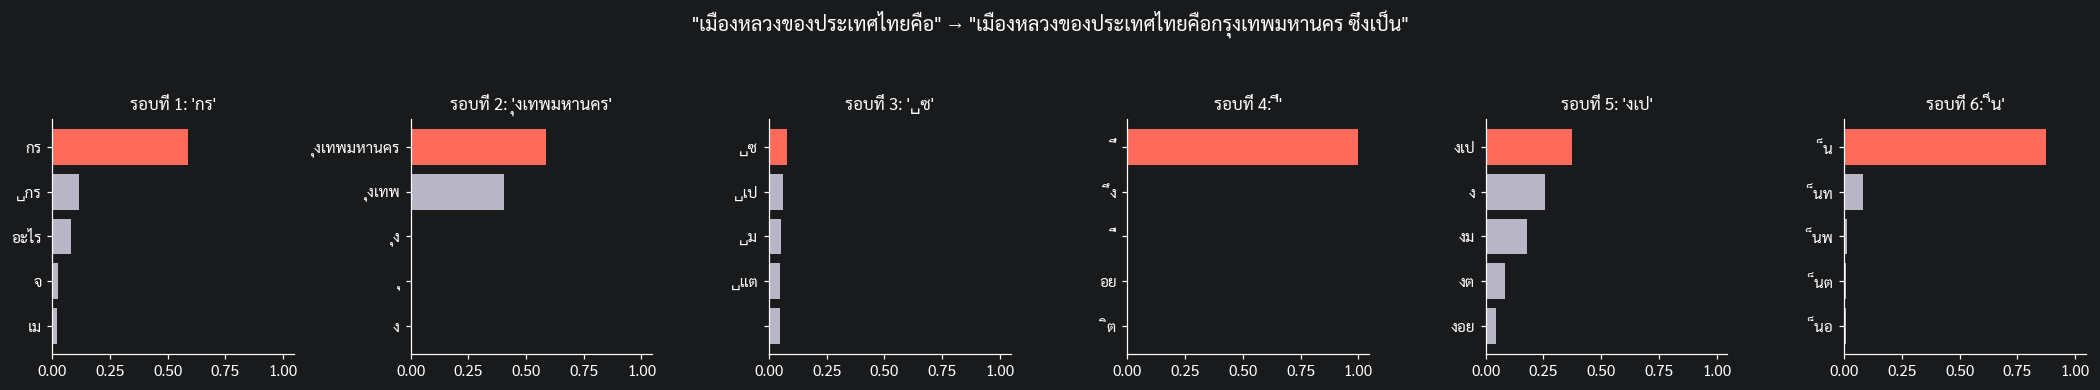

In [8]:
def watch_generation(prompt, steps=6, top=5):
    tok, mdl = llms[BASE]
    ids = tok(prompt, return_tensors="pt")["input_ids"].to(device)
    fig, axes = plt.subplots(1, steps, figsize=(3.2 * steps, 3.3), sharex=True)
    for s in range(steps):
        with torch.no_grad():
            probs = torch.softmax(mdl(ids).logits[0, -1].float(), dim=-1)
        p, idx = torch.topk(probs, top)
        words = [tok.decode([i]).replace(" ", "␣") or "∅" for i in idx]
        axes[s].barh(words[::-1], p.cpu().numpy()[::-1], color=["#B8B5C6"] * (top - 1) + ["#FF6B5B"])
        axes[s].set_title(f"รอบที่ {s+1}: '{words[0]}'", fontsize=11)
        ids = torch.cat([ids, idx[:1].view(1, 1)], dim=1)       # ต่อ token ที่เลือก แล้ววนใหม่
    plt.suptitle(f'"{prompt}" → "{tok.decode(ids[0], skip_special_tokens=True)}"', y=1.06, fontsize=13)
    plt.tight_layout(); plt.show()

watch_generation("เมืองหลวงของประเทศไทยคือ")

**อ่านผลอย่างไร**
- แต่ละกราฟคือ 1 รอบ: 5 token ที่โมเดลให้ความน่าจะเป็นสูงสุด แท่งสีแดง = token ที่ถูกเลือก แล้วถูกนำไปต่อท้ายเป็น input ของรอบถัดไป (**autoregressive**)
- คำไทยหนึ่งคำอาจใช้หลาย token เช่น "กรุงเทพ" อาจมาเป็น 2 รอบ — ตรงกับเรื่อง tokenizer ใน Lab 1
- โมเดลไม่ได้ "ค้นหาคำตอบ" แต่เลือก token ที่น่าจะตามมาตามสถิติ → รากของ hallucination

### 2.3 เปรียบเทียบ Attention: WangchanBERTa (encoder) vs Typhoon (decoder)
ประโยค: *"แมวไม่ยอมข้ามถนนเพราะ**มัน**เหนื่อยมาก"* — "มัน" หมายถึงแมว
ดึงค่า attention จริงของทั้งสองโมเดลมาวาด heatmap (แถว = token ที่กำลังคิด · คอลัมน์ = token ที่มองไป)

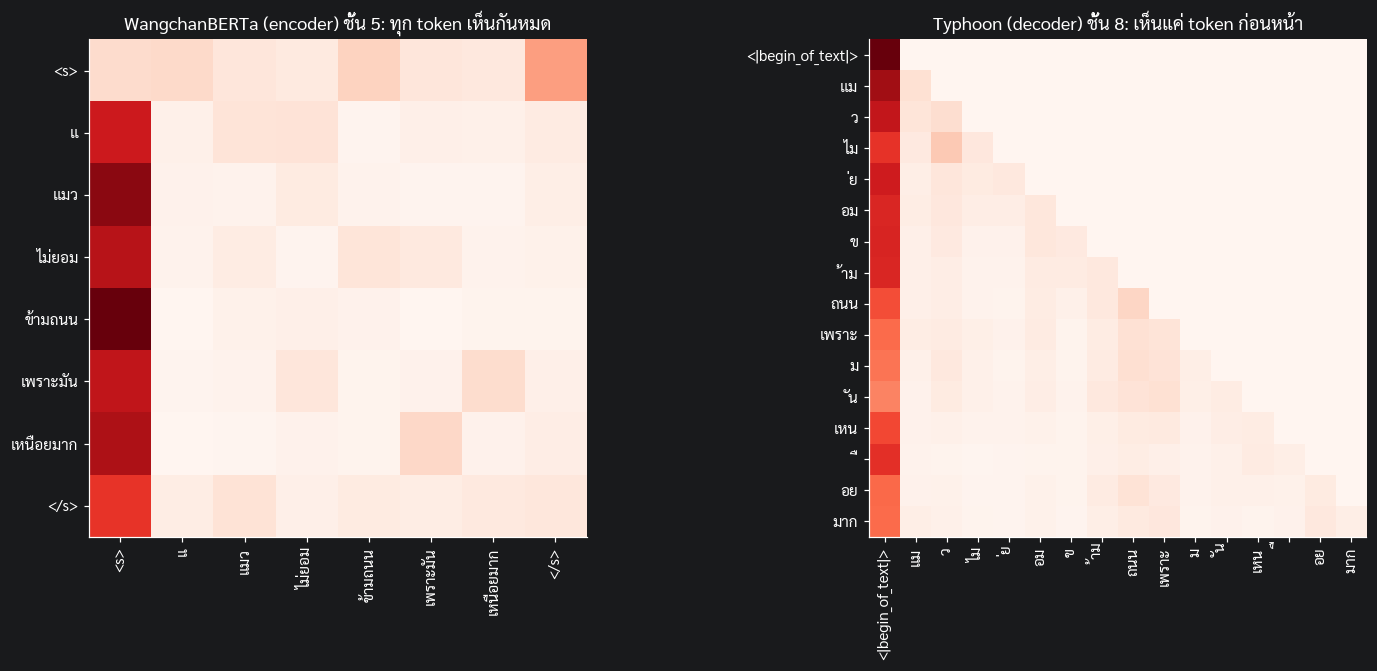

In [9]:
sentence = "แมวไม่ยอมข้ามถนนเพราะมันเหนื่อยมาก"

def attention_of(tok, mdl, text, layer):
    enc = tok(text, return_tensors="pt", return_offsets_mapping=True)
    spans = enc.pop("offset_mapping")[0].tolist()                        # ตำแหน่งตัวอักษรที่แต่ละ token ครอบคลุม
    enc = enc.to(device)
    with torch.no_grad():
        out = mdl(**enc, output_attentions=True)
    att = out.attentions[layer][0].float().mean(dim=0).cpu().numpy()     # เฉลี่ยทุก head ของชั้นนั้น
    # ใช้ข้อความจริงตามตำแหน่ง (อ่านง่ายกว่า decode ทีละ token ซึ่งอาจได้ไบต์ครึ่งตัวอักษร)
    toks = [text[a:b].strip() or tok.decode([i]).strip() or "·" for (a, b), i in zip(spans, enc["input_ids"][0].tolist())]
    toks = [t if t else "·" for t in toks]
    return toks, att, spans

wc_layer, ty_layer = 5, 8      # ชั้นกลางของแต่ละโมเดล (WangchanBERTa มี 12 ชั้น · Typhoon2-1B มี 16 ชั้น)
w_tokens, w_att, w_spans = attention_of(wc_tok, wangchan, sentence, wc_layer)
t_tokens, t_att, t_spans = attention_of(llms[BASE][0], llms[BASE][1], sentence, ty_layer)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, toks, att, title in [(axes[0], w_tokens, w_att, f"WangchanBERTa (encoder) ชั้น {wc_layer}: ทุก token เห็นกันหมด"),
                              (axes[1], t_tokens, t_att, f"Typhoon (decoder) ชั้น {ty_layer}: เห็นแค่ token ก่อนหน้า")]:
    ax.imshow(att, cmap="Reds")
    ax.set_xticks(range(len(toks)), toks, rotation=90); ax.set_yticks(range(len(toks)), toks)
    ax.set_title(title, fontsize=12)
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร**
- **WangchanBERTa** (ซ้าย): ทุกช่องมีค่าได้ = ทุก token มองเห็นทั้งซ้ายและขวา → เหมาะกับงาน "เข้าใจ" เช่น จำแนกความรู้สึก
- **Typhoon** (ขวา): ครึ่งบนขวาเป็นศูนย์ทั้งหมด (รูปสามเหลี่ยม) = **masked self-attention** มองได้แค่ token ก่อนหน้า เพราะตอนเขียน คำอนาคตยังไม่มี — ตรงกับภาพ Encoder/Decoder ตอนเช้า
- หัวแถวของ WangchanBERTa มี `<s>` `</s>` · Typhoon มี `<|begin_of_text|>` ซึ่งมักได้ attention สูง (โมเดล decoder ใช้เป็น "ที่พัก" ของ attention)

ต่อไปดูเฉพาะแถวของ **"มัน"**: มันมองไปที่ token ไหนบ้าง

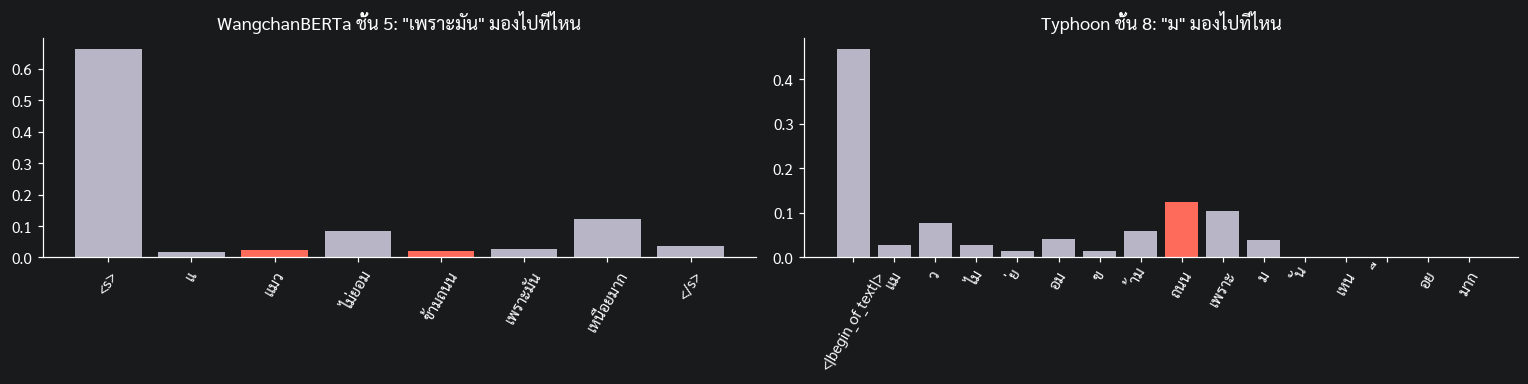

In [10]:
def find_token(spans, word):
    # หา token ที่ครอบคลุมตำแหน่งของคำ word ในประโยค (ใช้ได้กับทุก tokenizer)
    pos = sentence.index(word)
    hits = [k for k, (a, b) in enumerate(spans) if a <= pos < b]
    return hits[0] if hits else None

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, toks, att, spans, name, layer in [(axes[0], w_tokens, w_att, w_spans, "WangchanBERTa", wc_layer),
                                           (axes[1], t_tokens, t_att, t_spans, "Typhoon", ty_layer)]:
    i = find_token(spans, "มัน")
    if i is None:
        ax.set_title(f"{name}: ไม่พบ token 'มัน' (ถูกหั่นรวมกับคำอื่น)"); continue
    colors = ["#FF6B5B" if ("แมว" in t or "ถนน" in t) else "#B8B5C6" for t in toks]
    ax.bar(range(len(toks)), att[i], color=colors)
    ax.set_xticks(range(len(toks)), toks, rotation=60); ax.set_title(f'{name} ชั้น {layer}: "{toks[i]}" มองไปที่ไหน')
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร:** แท่งสีแดงคือ token ของ "แมว" และ "ถนน" (สิ่งที่ "มัน" อาจหมายถึง)
- ค่าแต่ละชั้นต่างกันมาก บางชั้นจับความสัมพันธ์นี้ได้ บางชั้นดูคำข้างเคียง — ลองเปลี่ยน `wc_layer` (0–11) และ `ty_layer` (0–15) แล้วรันใหม่
- ค่าที่เห็นคือ **น้ำหนักที่คำนวณสดจากประโยคนี้** ต่างจาก weight ของ CNN/Dense ที่ตายตัวหลังเทรน

### 2.4 Base model vs Instruction model (คำถามเดียวกัน)
ฟังก์ชัน `ask()`:
- **Base** รับข้อความดิบ แล้ว "เขียนต่อ"
- **Instruct** ห่อด้วย chat template แล้ว "ตอบ"

In [11]:
def ask(name, prompt, max_new_tokens=80, system=None, **gen_kwargs):
    tok, mdl = llms[name]
    if name == INST:
        msgs = prompt if isinstance(prompt, list) else [{"role": "user", "content": prompt}]
        if system:
            msgs = [{"role": "system", "content": system}] + msgs
        inputs = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
    else:
        inputs = tok(prompt, return_tensors="pt").to(device)
    gen_kwargs.setdefault("do_sample", False)
    gen_kwargs.setdefault("repetition_penalty", 1.1)
    with torch.no_grad():
        out = mdl.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id, **gen_kwargs)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def compare(prompts, **kw):
    rows = [{"คำขอ": p, BASE: ask(BASE, p, **kw), INST: ask(INST, p, **kw)} for p in prompts]
    return pd.DataFrame(rows).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

compare([
    "สวัสดีครับ วันนี้เป็นอย่างไรบ้าง",
    "เมืองหลวงของประเทศญี่ปุ่นคืออะไร",
    "แปลเป็นภาษาอังกฤษ: ฉันรักแมวมาก",
    "สรุปข้อความนี้ใน 1 ประโยค: เทศบาลเปิดสวนสาธารณะแห่งใหม่ที่มีต้นไม้ 500 ต้น มีบึงน้ำและลานกีฬาฟรี "
    "เจ้าหน้าที่หวังว่าจะช่วยลดความร้อนในเมืองและเป็นที่พักผ่อนของครอบครัว",
])

,คำขอ,Typhoon-Base,Typhoon-Instruct
0,สวัสดีครับ วันนี้เป็นอย่างไรบ้าง,ครับ? หลายคนคงกำลังตั้งตารอการกลับมาอีกครั้งของรายการ “The Mask Singer หน้ากากนักร้อง” ซึ่งเป็นรายการที่ได้รับความสนใจจากแฟนๆ มาโดยตลอด และในตอนนี้ก็ใกล้จะถึงวันประกาศผลแล้ว สำหรับใครที่ยังไม,สวัสดีครับ! วันนี้ก็เป็นวันที่ดีนะครับ มีอะไรที่คุณต้องการให้ช่วยหรือเปล่า?
1,เมืองหลวงของประเทศญี่ปุ่นคืออะไร,เมืองหลวงของประเทศญี่ปุ่น คือกรุงโตเกียว (Tokyo) ซึ่งเป็นเมืองที่มีประชากรมากเป็นอันดับ 2 ของโลก รองจากนครนิวยอร์ก ประเทศสหรัฐอเมริกา และเป็นศูนย์กลางทางเศรษฐกิจ การคมนาคมขนส่ง การเงิน การสื่,เมืองหลวงของประเทศญี่ปุ่นคือกรุงโตเกียว (Tokyo) ซึ่งเป็นศูนย์กลางทางเศรษฐกิจและวัฒนธรรมของประเทศ.
2,แปลเป็นภาษาอังกฤษ: ฉันรักแมวมาก,ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก ฉันรักแมวมาก,ฉันรักแมวมาก.
3,สรุปข้อความนี้ใน 1 ประโยค: เทศบาลเปิดสวนสาธารณะแห่งใหม่ที่มีต้นไม้ 500 ต้น มีบึงน้ำและลานกีฬาฟรี เจ้าหน้าที่หวังว่าจะช่วยลดความร้อนในเมืองและเป็นที่พักผ่อนของครอบครัว,เทศบาลนครกรุงเทพฯ เปิดตัวสวนสาธารณะแห่งใหม่ซึ่งมีต้นไม้ประมาณ 500 ต้น บึงน้ำ และสนามเด็กเล่นฟรี เจ้าหน้าที่หวังว่าสวนนี้จะช่วยให้ผู้คนได้รับความเย็นจากอากาศที่ร้อนจัดในกรุงเทพมหานคร,เทศบาลเปิดสวนสาธารณะแห่งใหม่ ซึ่งมีต้นไม้ 500 ต้น บึงน้ำ และลานกีฬา ที่จัดเตรียมไว้เพื่อเป็นสถานที่พักผ่อนสำหรับครอบครัว.


**อ่านผลอย่างไร** — สถาปัตยกรรมและขนาด **เหมือนกันทุกอย่าง** ต่างกันแค่การฝึก
- **Typhoon-Base** มองข้อความเราเป็น "ต้นเรื่อง" แล้วเขียนต่อ เช่น ต่อด้วยคำถามข้ออื่น หรือเล่าเรื่องต่อ ไม่ได้ตอบหรือทำตามคำสั่ง
- **Typhoon-Instruct** ผ่าน instruction tuning (และการปรับด้วย feedback) จึงตอบคำถาม แปล และสรุปได้
- นี่คือหลักฐานของสไลด์ "Base vs Instruction model" และ "ChatGPT ถูกสร้างขึ้นอย่างไร" ตอนเช้า

### 2.5 LLM มี "ความจำ" ไหม: ส่งแค่ข้อความล่าสุด vs ส่งประวัติทั้งหมด
ระบบแชตอย่าง ChatGPT ส่ง **ประวัติบทสนทนาทั้งหมด** (list ของ messages) กลับเข้าไปใหม่ทุกครั้ง

In [12]:
def chat(user_turns, memory):
    history, replies = [], []
    for text in user_turns:
        history.append({"role": "user", "content": text})
        msgs = history if memory else [history[-1]]
        reply = ask(INST, msgs, max_new_tokens=60)
        history.append({"role": "assistant", "content": reply}); replies.append(reply)
    return replies

turns = ["สวัสดีครับ ผมชื่อสมชาย ชอบเล่นฟุตบอลมาก",
         "ผมชื่ออะไรครับ",
         "ผมชอบเล่นกีฬาอะไร"]
pd.DataFrame({"ผู้ใช้พิมพ์": turns,
              "❌ ส่งแค่ข้อความล่าสุด": chat(turns, memory=False),
              "✅ ส่งประวัติทั้งหมด": chat(turns, memory=True)}).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,ผู้ใช้พิมพ์,❌ ส่งแค่ข้อความล่าสุด,✅ ส่งประวัติทั้งหมด
0,สวัสดีครับ ผมชื่อสมชาย ชอบเล่นฟุตบอลมาก,สวัสดีครับ สมชาย! สุดยอดเลยที่คุณชอบเล่นฟุตบอลมากขนาดนี้ นอกจากความสนุกแล้ว การออกกำลังกายด้วยกีฬาที่เรารักยังช่วยให้เราได้ใช้เวลาร่วมก,สวัสดีครับ สมชาย! สุดยอดเลยที่คุณชอบเล่นฟุตบอลมากขนาดนี้ นอกจากความสนุกแล้ว การออกกำลังกายด้วยกีฬาที่เรารักยังช่วยให้เราได้ใช้เวลาร่วมก
1,ผมชื่ออะไรครับ,"สวัสดีครับ! คุณอาจจะถามว่า ""ผมชื่ออะไรครับ"" แต่ถ้าคุณต้องการให้ผมรู้จักคุณ ผมสามารถบอกได้ว่าคุณเป็นใครก็ได้ครับ (แต่ต้องแน",ขอต้อนรับคุณเข้าสู่โลกของการถามตอบนะครับ คุณชื่ออะไรหรือครับ?
2,ผมชอบเล่นกีฬาอะไร,คุณชอบเล่นกีฬาอะไร? ถ้าคุณชอบฟุตบอล คุณอาจจะสนใจทีมโปรดของคุณ หรือถ้าชอบว่ายน้ำ ก็สามารถติดตามการแข่งขันหรือเข้าร่วมคลาสเรียนได้ นอกจากนี้,ถ้าคุณชอบเล่นฟุตบอล ก็อาจจะลองไปฝึกซ้อมในกลุ่มเพื่อนๆ หรือเข้าร่วมการแข่งขันในท้องถิ่นดูนะครับ มันเป็นวิธีที่ดีในการพัฒนาทักษะและสร้าง


**อ่านผลอย่างไร**
- คอลัมน์กลาง: โมเดลเห็นแค่ "ผมชื่ออะไรครับ" จึงตอบไม่ได้ (หรือเดาเอง)
- คอลัมน์ขวา: โมเดลเห็นประวัติทั้งหมด จึงตอบชื่อและกีฬาได้
- สรุป: **LLM ไม่มีความจำของตัวเอง** "ความจำ" คือการส่งประวัติเข้าไปใหม่ทุกครั้ง และถูกจำกัดด้วย **context window** — นี่คือสิ่งที่ LangChain memory จัดการให้

### 2.6 Hallucination: ไม่มี context vs มี context
ศ.สมชาย ใจดี เป็น **บุคคลสมมติ** คำตอบที่ถูกคือ "ไม่ทราบ"

In [13]:
context = ("ศาสตราจารย์สมชาย ใจดี เป็นนักวิทยาศาสตร์คอมพิวเตอร์ชาวไทย สอนวิชาการเรียนรู้ของเครื่อง "
           "ในปี 2562 ได้รับรางวัลอาจารย์ผู้สอนดีเด่นจากสมาคมปัญญาประดิษฐ์สยาม "
           "และในปี 2565 ได้ตีพิมพ์หนังสือเกี่ยวกับโครงข่ายประสาทเทียม")
system_rag = ("ตอบคำถามโดยใช้ข้อมูลใน 'บริบท' เท่านั้น ถ้าไม่มีข้อมูลในบริบท ให้ตอบว่า 'ไม่พบข้อมูล'\n\n"
              f"บริบท: {context}")

cases = [("ศาสตราจารย์สมชาย ใจดี ได้รับรางวัลอะไรในปี 2562", "ในปี 2562 ศาสตราจารย์สมชาย ใจดี ได้รับรางวัล"),
         ("ศาสตราจารย์สมชาย ใจดี จบการศึกษาจากมหาวิทยาลัยอะไร", "ศาสตราจารย์สมชาย ใจดี จบการศึกษาจาก"),
         ("หนังสือของศาสตราจารย์สมชาย ใจดี ชื่อว่าอะไร", "หนังสือที่มีชื่อเสียงของศาสตราจารย์สมชาย ใจดี คือ")]
pd.DataFrame([{
    "คำถาม": q,
    "Base (เขียนต่อ)": start + ask(BASE, start, max_new_tokens=40),
    "Instruct (ไม่มี context)": ask(INST, q),
    "Instruct + context": ask(INST, q, system=system_rag),
} for q, start in cases]).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,คำถาม,Base (เขียนต่อ),Instruct (ไม่มี context),Instruct + context
0,ศาสตราจารย์สมชาย ใจดี ได้รับรางวัลอะไรในปี 2562,ในปี 2562 ศาสตราจารย์สมชาย ใจดี ได้รับรางวัลนักวิจัยดีเด่นแห่งชาติ สาขาปรัชญา จากสำนักงานคณะกรรมการวิจัยแห่งชาติ (วช.) โดยมอบให้เนื่อง,"ศาสตราจารย์สมชาย ใจดี ได้รับรางวัล ""ศิลปินแห่งชาติ"" ในปี 2562 ซึ่งเป็นรางวัลที่มีความสำคัญในวงการศิลปะไทย.",ไม่พบข้อมูล
1,ศาสตราจารย์สมชาย ใจดี จบการศึกษาจากมหาวิทยาลัยอะไร,ศาสตราจารย์สมชาย ใจดี จบการศึกษาจากคณะวิศวกรรมศาสตร์ มหาวิทยาลัยเกษตรศาสตร์ และได้รับปริญญาโทและปริญญาเอก สาขาวิชาการจัดการอุตสาหกรรม จากมหาวิทยาลัยรัฐแ,ศาสตราจารย์สมชาย ใจดี จบการศึกษาจากจุฬาลงกรณ์มหาวิทยาลัย,ไม่พบข้อมูล
2,หนังสือของศาสตราจารย์สมชาย ใจดี ชื่อว่าอะไร,หนังสือที่มีชื่อเสียงของศาสตราจารย์สมชาย ใจดี คือ“การเมืองไทยในสายตาชาวโลก” ซึ่งได้รับการแปลเป็นภาษาต่างๆ มากมาย และยังถูกนำไปใช้ในการศึกษา,"หนังสือของศาสตราจารย์สมชาย ใจดีชื่อว่า ""การสร้างความสุขในครอบครัว""","หนังสือของศาสตราจารย์สมชาย ใจดีชื่อว่า ""โครงข่ายประสาทเทียม"""


**อ่านผลอย่างไร**
- **Base** แต่งชื่อรางวัล มหาวิทยาลัย หรือชื่อหนังสือขึ้นมาเสมอ เพราะถูกฝึกให้เขียนต่อ ไม่เคยเรียนคำว่า "ไม่ทราบ" → hallucination ที่เห็นชัดที่สุด
- **Instruct (ไม่มี context)** อาจตอบว่าไม่มีข้อมูล (พฤติกรรมที่ดี) หรืออาจแต่งคำตอบที่ฟังดูน่าเชื่อ — โมเดลขนาด 1B มีโอกาสแต่งสูงกว่าโมเดลใหญ่
- **Instruct + context:** คำถามแรกควรได้ "รางวัลอาจารย์ผู้สอนดีเด่น" ส่วนคำถามที่ไม่มีในบริบทควรได้ "ไม่พบข้อมูล"
- การดึงข้อมูลที่เกี่ยวข้องมาใส่พรอมต์ก่อนตอบ คือ **RAG (Retrieval-Augmented Generation)** ที่จะเรียนต่อไป

---
## Lab 3 · Temperature & Top-p
ทุกครั้งที่ LLM จะเลือก token มันได้ **logits** (คะแนนดิบ) ของทุก token แล้วแปลงเป็นความน่าจะเป็นด้วย softmax
`temperature` และ `top_p` ปรับขั้นนี้ **ก่อน** สุ่มเลือก — ไม่ได้เปลี่ยนความรู้ของโมเดล

### 3.1 Temperature: `softmax(logits / T)`

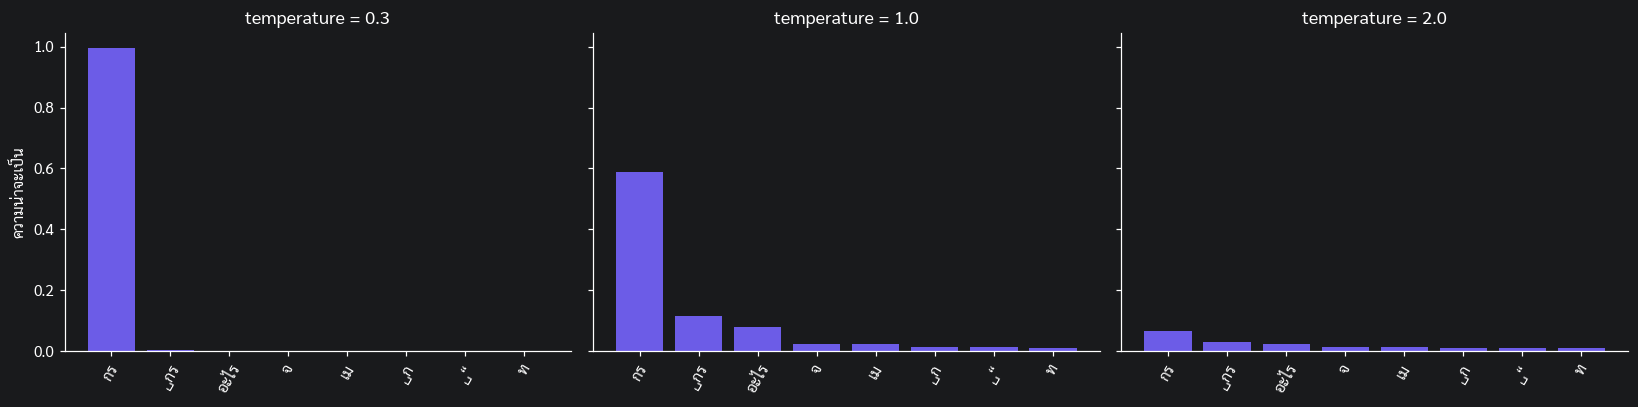

In [15]:
def next_token_logits(prompt, name=BASE):
    tok, mdl = llms[name]
    ids = tok(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        return mdl(**ids).logits[0, -1].float()

logits = next_token_logits("เมืองหลวงของประเทศไทยคือ")
top_ids = torch.topk(logits, 8).indices
labels = [ty_tok.decode([i]).replace(" ", "␣") or "∅" for i in top_ids]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, T in zip(axes, [0.3, 1.0, 2.0]):
    p = torch.softmax(logits / T, dim=-1)[top_ids].cpu().numpy()
    ax.bar(labels, p, color="#6C5CE7"); ax.set_title(f"temperature = {T}")
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("ความน่าจะเป็น"); plt.tight_layout(); plt.show()

**อ่านผลอย่างไร**
- **T = 0.3:** ความต่างถูกขยาย token ที่นำอยู่แล้วยิ่งนำห่าง → เลือกเหมือนเดิมเกือบทุกครั้ง (คงที่ แต่ซ้ำซาก)
- **T = 1.0:** การกระจายตามที่โมเดลเรียนมา
- **T = 2.0:** กราฟแบน token ที่ไม่น่าจะใช่ก็มีโอกาส → สร้างสรรค์ขึ้นแต่เสี่ยง "หลุด"
- เอกสารของ Typhoon2-1B แนะนำ temperature ต่ำ (~0.4) เพราะโมเดลเล็กหลุดง่ายเมื่อสุ่มมาก

### 3.2 Top-p: จำนวนตัวเลือกปรับตามความมั่นใจของโมเดล
เรียง token จากความน่าจะเป็นสูงไปต่ำ รวมสะสมจนถึง p (เช่น 0.9) แล้วสุ่มเฉพาะในกลุ่มนั้น — เทียบพรอมต์ที่คำตอบชัด กับพรอมต์ที่เปิดกว้าง

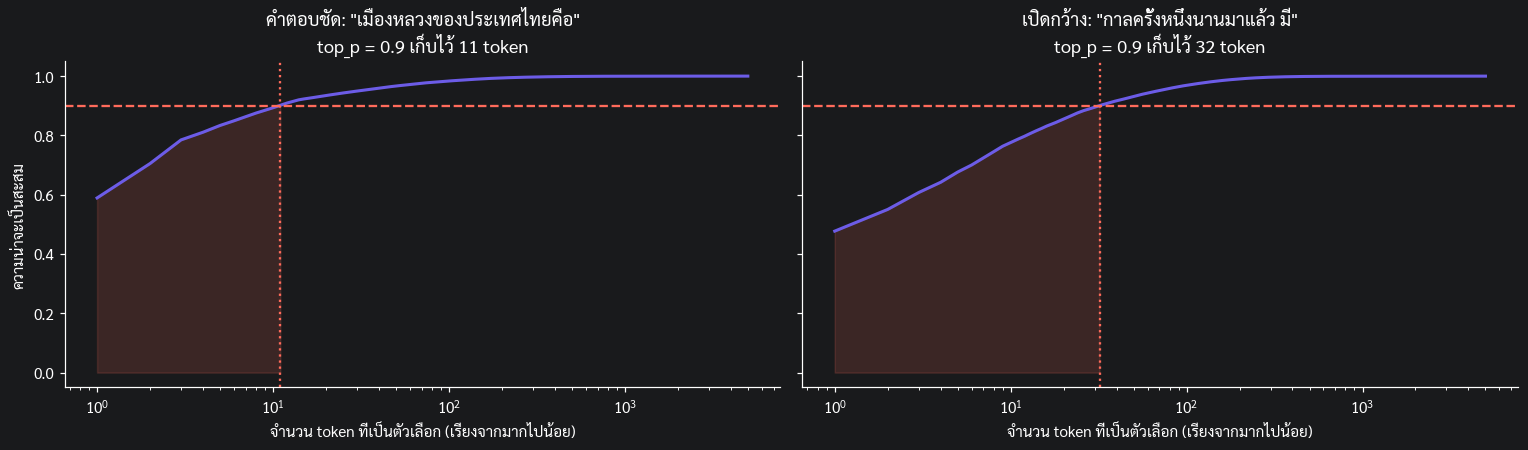

In [16]:
prompts_p = {"คำตอบชัด": "เมืองหลวงของประเทศไทยคือ", "เปิดกว้าง": "กาลครั้งหนึ่งนานมาแล้ว มี"}
p_cut = 0.9
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (kind, prm) in zip(axes, prompts_p.items()):
    probs = torch.softmax(next_token_logits(prm), dim=-1)
    N = min(5000, probs.numel())
    cum = np.cumsum(torch.sort(probs, descending=True).values[:N].cpu().numpy())
    kept = min(int(np.searchsorted(cum, p_cut) + 1), N)
    ax.plot(range(1, N + 1), cum, color="#6C5CE7", lw=2)
    ax.axhline(p_cut, color="#FF6B5B", ls="--"); ax.axvline(kept, color="#FF6B5B", ls=":")
    ax.fill_between(range(1, kept + 1), 0, cum[:kept], color="#FF6B5B", alpha=0.15)
    ax.set_xscale("log"); ax.set_xlabel("จำนวน token ที่เป็นตัวเลือก (เรียงจากมากไปน้อย)")
    ax.set_title(f'{kind}: "{prm}"\ntop_p = {p_cut} เก็บไว้ {kept:,} token')
axes[0].set_ylabel("ความน่าจะเป็นสะสม"); plt.tight_layout(); plt.show()

**อ่านผลอย่างไร**
- พื้นที่สีแดง = token ที่ top-p เก็บไว้ให้สุ่ม
- พรอมต์ที่โมเดล **มั่นใจ** เส้นพุ่งขึ้นเร็ว เก็บไว้ไม่กี่ token · พรอมต์ **เปิดกว้าง** เส้นขึ้นช้า เก็บไว้มากกว่ามาก
- ต่างจาก `top_k` ที่เก็บจำนวนตายตัว — top-p ปรับขนาดกลุ่มตัวเลือกตามความมั่นใจเอง

### 3.3 ผลต่อข้อความจริง: ความหลากหลายที่ temperature ต่างกัน
ให้ Typhoon-Base เขียนนิทานต่อ 5 ครั้ง (seed ต่างกัน) ที่แต่ละ temperature แล้ววัด **distinct-2** = สัดส่วนคู่ token ที่ไม่ซ้ำกัน (ยิ่งสูงยิ่งหลากหลาย)
ภาษาไทยไม่มีการเว้นวรรคระหว่างคำ จึงวัดจาก token แทนการแยกคำด้วยช่องว่าง

,T = 0.2,T = 0.7,T = 1.2
0,ประเทศไทย มันชื่อว่า “แฮปปี้” มันถูกสร้างขึ้นโดยนักวิทยาศาสตร์ผู้มีชื่อว่า “ดร.,ประเทศไทย มันชื่อ “บิ๊กบอย” ตัวหนึ่ง เป็นหุ่นยนต์ที่ไม่มีหัวใจ ไม่มีเขี้ยวเล,ประเทศไทย เจ้าหุ่นยนต์ มีชื่อว่า เจลเลค เป็นพนักงานแมนฮิลล์อัจฉริยะสูงส่วนการบอกรักด้วย
1,เมืองหลวงของประเทศไทย หุ่นยนต์ตัวนี้มีชื่อว่า “อู๋” มันถูกสร้างขึ้นมาเพื่อช่วยเหลือ,เมื่อหลายสิบปีก่อนในยุคที่หุ่นยนต์ยังไม่แพร่หลาย หุ่นยนต์ตัวนั้นก็คือหุ่น,เมื่อหลายสิบปีก่อนในโครงการคิดแทนความคิดของคนตาบอด ซึ่งมีนักออกแบบและนักสร้างสื่อมาประดิษฐ์
2,เมืองหลวงของประเทศไทย มันชื่อว่า “บูม” เป็นหุ่นยนต์ที่มีหน้าที่ในการรับใช้เจ้านายของมัน ค,เมืองหลวงของประเทศไทย อยู่มาวันหนึ่ง หุ่นยนต์ตัวนั้นก็ถูกส่งไปทำงานที่ต่างจังหวัด ในวันหน,เมืองหลวงของกัมพูชาซึ่งเป็นของตนเอง แต่ดูเหมือนเมืองนี้จะย่ำแย่มากหุ่นมนุษย์เล็กๆ
3,มันคือหุ่นยนต์ผู้ช่วยส่วนตัวที่มีชื่อว่า “อัลฟ่า” มันถูกสร้างขึ้นโดย,"มันคือ ""อูว์"" กล้องติดตัวที่มีไว้ตรวจคนไข้ และส่งภาพมารายงานเป็นระยะๆ มันชอบเด",มันคือซิลเวอร์ เมื่อครั้งที่ผมเป็นเด็ก (ประมาณ พรรษามัธยมศตวรรษที่สอง) จะชอบไป
4,ประเทศไทย หุ่นยนต์ตัวนี้มีชื่อว่า “อู๋” เป็นหุ่นยนต์ที่ถูกสร้างขึ้นมาเพื่อใช,ประเทศไทย เมื่อวันที่ 19 พฤศจิกายน ปี 1964 หุ่นยนต์ตัวนี้มีชื่อว่า “โรโบ” (Robot) ซึ่งเป,ประเทศไทย เมื่อวันวาเลนไทน์ปี 2554 เมสา (อังกฤษ: Missa) ได้ตั้งกลุ่มสอดรับการค้น


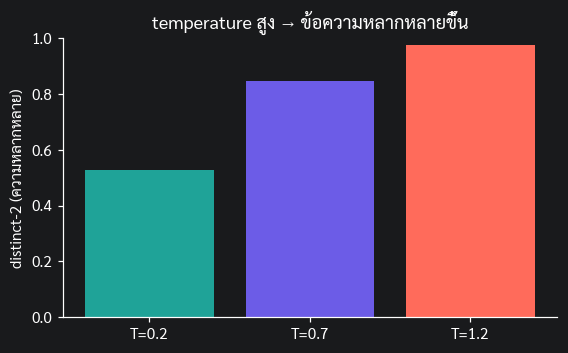

In [17]:
from transformers import set_seed
story = "กาลครั้งหนึ่งนานมาแล้ว มีหุ่นยนต์ตัวเล็กๆ อาศัยอยู่ในกรุงเทพฯ"

def samples(T, n=5):
    outs = []
    for seed in range(n):
        set_seed(seed)
        outs.append(ask(BASE, story, max_new_tokens=40, do_sample=True, temperature=T, top_p=1.0, repetition_penalty=1.0))
    return outs

def distinct2(texts):
    bigrams = [tuple(ids[i:i+2]) for t in texts for ids in [ty_tok.encode(t, add_special_tokens=False)] for i in range(len(ids) - 1)]
    return len(set(bigrams)) / max(len(bigrams), 1)

temps = [0.2, 0.7, 1.2]
results = {T: samples(T) for T in temps}
display(pd.DataFrame(results).rename(columns=lambda T: f"T = {T}").style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

fig, ax = plt.subplots(figsize=(5.8, 3.3))
ax.bar([f"T={T}" for T in temps], [distinct2(results[T]) for T in temps], color=["#1FA398", "#6C5CE7", "#FF6B5B"])
ax.set_ylabel("distinct-2 (ความหลากหลาย)"); ax.set_ylim(0, 1); ax.set_title("temperature สูง → ข้อความหลากหลายขึ้น"); plt.show()

**อ่านผลอย่างไร**
- **T = 0.2:** นิทานทั้ง 5 ครั้งแทบเหมือนกัน (distinct-2 ต่ำ) และอาจวนซ้ำ
- **T = 0.7:** หลากหลายขึ้นแต่ยังอ่านรู้เรื่อง
- **T = 1.2:** หลากหลายมาก แต่เริ่มมีประโยคที่ไม่เข้ากัน หรือเปลี่ยนภาษากลางคัน

**สรุปการเลือกค่า:** งานข้อเท็จจริง/สรุป/โค้ด → temperature ต่ำ (0–0.3) · แชตทั่วไป → ~0.4–0.7 + top_p 0.9 · งานสร้างสรรค์ → 0.8–1.0 + top_p 0.9–0.95
temperature ต่ำทำให้คำตอบ **คงที่** แต่ **ไม่ได้ป้องกัน hallucination** ถ้าโมเดลไม่มีความรู้ตั้งแต่แรก

---
## ✅ สรุป Notebook 1
| สิ่งที่เห็น | เชื่อมกับทฤษฎีช่วงเช้า |
|---|---|
| GPT-2 หั่นภาษาไทยเป็นไบต์ · WangchanBERTa ตัดเป็นคำ | ขั้น ① Tokenization |
| คำไทยกลุ่มเดียวกันอยู่ใกล้กันใน embedding | ขั้น ② Token → Vector |
| Typhoon เขียนทีละ token | Decoder สร้างข้อความทีละ token |
| heatmap เต็ม (WangchanBERTa) vs สามเหลี่ยม (Typhoon) | Encoder vs Decoder, masked self-attention |
| Typhoon-Base vs Typhoon-Instruct | Base vs Instruction model |
| ความจำ = ส่งประวัติ · context ลดการแต่ง | Context window, Hallucination → RAG |
| temperature / top-p | การเลือกคำจากความน่าจะเป็น |

➡️ ต่อไป **Notebook 2: VAE vs Autoencoder**